In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import os

print("Input directory exists:", os.path.exists("/kaggle/input"))

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))


Input directory exists: True
/kaggle/input/datasets/salmanthecodepro/gene-expression-cancer-rna-seq-levels/data.csv
/kaggle/input/datasets/salmanthecodepro/gene-expression-cancer-rna-seq-levels/labels.csv


In [3]:

import pandas as pd
import numpy as np
import os
import json
import time
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

BASE = "/kaggle/input/datasets/salmanthecodepro/gene-expression-cancer-rna-seq-levels"
OUT = "/kaggle/working/oncolens"

os.makedirs(OUT, exist_ok=True)

data = pd.read_csv(f"{BASE}/data.csv")
labels = pd.read_csv(f"{BASE}/labels.csv")

merged = data.merge(
    labels[["Unnamed: 0", "Class"]],
    on="Unnamed: 0",
    how="inner",
    validate="one_to_one"
)

X = merged.drop(columns=["Unnamed: 0", "Class"])
X = X.apply(pd.to_numeric, errors="raise")
y = merged["Class"].astype(str)

assert len(merged) == len(data) == len(labels)
assert X.notna().all().all()
assert np.isfinite(X.to_numpy()).all()

print("Aligned samples:", len(merged))
print("Gene features:", X.shape[1])
print("\nClass counts:\n", y.value_counts())
print("\nDATA VALIDATION: PASS")


Aligned samples: 801
Gene features: 20531

Class counts:
 Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

DATA VALIDATION: PASS


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())


Training samples: 640
Testing samples: 161

Training class distribution:
Class
BRCA    240
KIRC    116
LUAD    113
PRAD    109
COAD     62
Name: count, dtype: int64


In [5]:

model = Pipeline([
    ("remove_constant", VarianceThreshold(threshold=0.0)),
    ("rf", RandomForestClassifier(
        n_estimators=150,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()
model.fit(X_train, y_train)
training_time = time.time() - start

print(f"Training completed in {training_time:.2f} seconds!")


Training completed in 2.49 seconds!


In [6]:

pred = model.predict(X_test)

accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")
classes = sorted(y.unique())

print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Test macro F1: {macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred,
    labels=classes,
    zero_division=0
))


Test accuracy: 0.9938 (99.38%)
Test macro F1: 0.9947

Classification report:
              precision    recall  f1-score   support

        BRCA       0.98      1.00      0.99        60
        COAD       1.00      1.00      1.00        16
        KIRC       1.00      1.00      1.00        30
        LUAD       1.00      0.96      0.98        28
        PRAD       1.00      1.00      1.00        27

    accuracy                           0.99       161
   macro avg       1.00      0.99      0.99       161
weighted avg       0.99      0.99      0.99       161



Rows = Actual | Columns = Predicted
      BRCA  COAD  KIRC  LUAD  PRAD
BRCA    60     0     0     0     0
COAD     0    16     0     0     0
KIRC     0     0    30     0     0
LUAD     1     0     0    27     0
PRAD     0     0     0     0    27


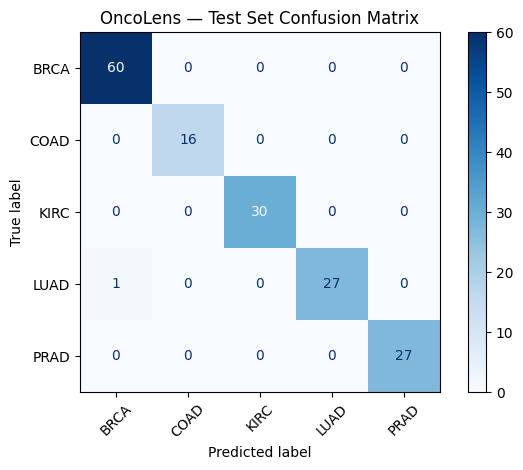

In [7]:

cm = confusion_matrix(y_test, pred, labels=classes)

print("Rows = Actual | Columns = Predicted")
print(pd.DataFrame(cm, index=classes, columns=classes))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("OncoLens — Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=160)
plt.show()


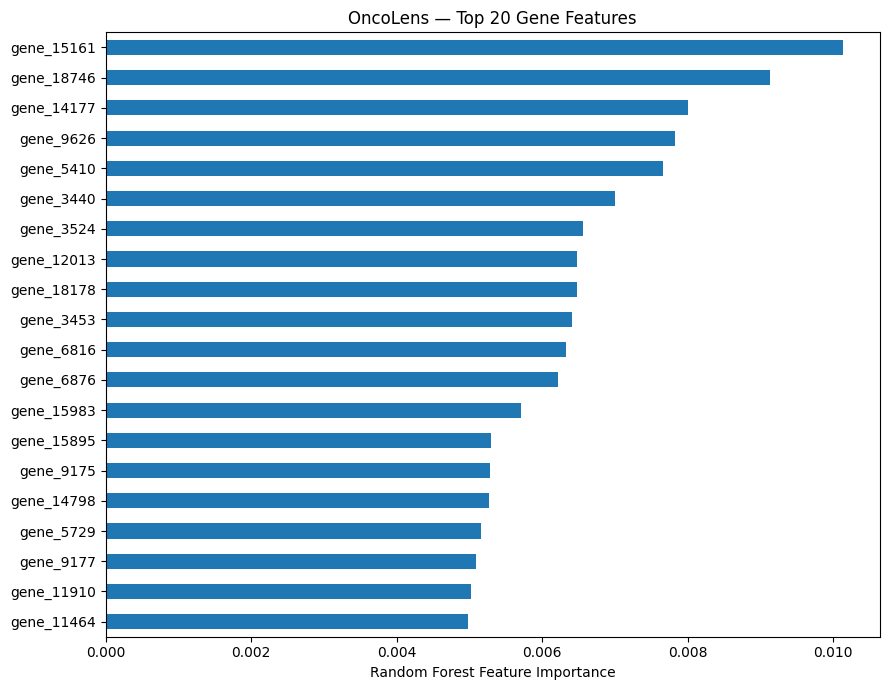

Top 20 genes:
gene_15161    0.010139
gene_18746    0.009131
gene_14177    0.008013
gene_9626     0.007832
gene_5410     0.007657
gene_3440     0.007000
gene_3524     0.006566
gene_12013    0.006477
gene_18178    0.006475
gene_3453     0.006411
gene_6816     0.006324
gene_6876     0.006222
gene_15983    0.005707
gene_15895    0.005301
gene_9175     0.005291
gene_14798    0.005277
gene_5729     0.005159
gene_9177     0.005093
gene_11910    0.005023
gene_11464    0.004980
Name: importance, dtype: float64


In [8]:

selector = model.named_steps["remove_constant"]
rf = model.named_steps["rf"]

selected_genes = X.columns[selector.get_support()]

importance = pd.Series(
    rf.feature_importances_,
    index=selected_genes,
    name="importance"
).sort_values(ascending=False)

importance.rename_axis("gene").reset_index().to_csv(
    f"{OUT}/gene_importance.csv",
    index=False
)

top20 = importance.head(20).sort_values()

top20.plot(kind="barh", figsize=(9, 7))
plt.title("OncoLens — Top 20 Gene Features")
plt.xlabel("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(f"{OUT}/top20_gene_importance.png", dpi=160)
plt.show()

print("Top 20 genes:")
print(importance.head(20))


In [9]:

model_path = f"{OUT}/oncolens_random_forest.joblib"

joblib.dump(model, model_path)
joblib.dump(
    list(X.columns),
    f"{OUT}/feature_columns.joblib"
)

metrics = {
    "dataset_samples": int(len(X)),
    "gene_features": int(X.shape[1]),
    "train_samples": int(len(X_train)),
    "test_samples": int(len(X_test)),
    "classes": classes,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "training_seconds": float(training_time),
    "random_state": 42,
    "n_estimators": 150,
    "test_split": 0.20
}

with open(f"{OUT}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Verify that the saved model reloads correctly
reloaded = joblib.load(model_path)
pred_reloaded = reloaded.predict(X_test)

assert np.array_equal(pred, pred_reloaded)

print("MODEL RELOAD TEST: PASS")
print("\nSaved artifacts:")
print(sorted(os.listdir(OUT)))


MODEL RELOAD TEST: PASS

Saved artifacts:
['confusion_matrix.png', 'feature_columns.joblib', 'gene_importance.csv', 'metrics.json', 'oncolens_random_forest.joblib', 'top20_gene_importance.png']


In [10]:

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_scores = cross_validate(
    clone(model),
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=1
)

dummy_scores = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro"
    },
    n_jobs=1
)

print("RANDOM FOREST — 5-FOLD CV")
print("Accuracy:", np.round(rf_scores["test_accuracy"], 4))
print("Mean accuracy:", round(rf_scores["test_accuracy"].mean(), 4))
print("Mean macro F1:", round(rf_scores["test_macro_f1"].mean(), 4))

print("\nMAJORITY-CLASS BASELINE")
print("Mean accuracy:", round(dummy_scores["test_accuracy"].mean(), 4))
print("Mean macro F1:", round(dummy_scores["test_macro_f1"].mean(), 4))


RANDOM FOREST — 5-FOLD CV
Accuracy: [1.     1.     1.     0.9922 0.9922]
Mean accuracy: 0.9969
Mean macro F1: 0.9974

MAJORITY-CLASS BASELINE
Mean accuracy: 0.375
Mean macro F1: 0.1091


In [11]:
import os

OUT = "/kaggle/working/oncolens"
os.makedirs(OUT, exist_ok=True)

print("Output folder:", OUT)
print("Folder exists:", os.path.exists(OUT))
print("Files available:", os.listdir(OUT))

Output folder: /kaggle/working/oncolens
Folder exists: True
Files available: ['confusion_matrix.png', 'gene_importance.csv', 'oncolens_random_forest.joblib', 'feature_columns.joblib', 'top20_gene_importance.png', 'metrics.json']


In [12]:
import zipfile
import os

zip_path = "/kaggle/working/OncoLens_Phase1.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(OUT):
        full_path = os.path.join(OUT, filename)
        if os.path.isfile(full_path):
            z.write(full_path, arcname=filename)

print("ZIP created:", os.path.exists(zip_path))
print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))
print("Files included:", zipfile.ZipFile(zip_path).namelist())

ZIP created: True
ZIP size (MB): 0.59
Files included: ['confusion_matrix.png', 'gene_importance.csv', 'oncolens_random_forest.joblib', 'feature_columns.joblib', 'top20_gene_importance.png', 'metrics.json']
